# Sparsity: every run evaluated with 32 and 16 laser beams (one-off)

Runtime -> Change runtime type -> **GPU** (T4 is enough). Set cell 1, then **Runtime -> Run all**.

For every finished run on Drive (NDT-Transformer `ndt`, BEVPlace++ `bev`, own NDT network `myndt`, and the official
BEVPlace++ checkpoint) this runs the evaluation type `sparsity` (`src/lpr/evals.py`) on its last checkpoint, without
retraining:

- **64 beams**: the run's own variant (same as `seqs_heading`);
- **`both`**: map and queries from the 32 / 16-beam variant (a cheaper LiDAR everywhere);
- **`query`**: map from 64 beams, queries from 32 / 16 beams (a cheaper LiDAR localising in a good map).

The sparse variants (`<date>_beams32_<hash>`, `<date>_beams16_<hash>`) were built on Azure; this notebook copies them
from the blob container to Drive and to this machine (SAS URL in Colab Secrets as `AZURE_SAS`, read + list is enough).
Results: `<run>/eval/sparsity/<checkpoint>/` (`summary.csv`, `sparsity.png`), and the table at the end
(`MyDrive/lpr/sparsity_all_runs.csv`). A complete evaluation is not repeated, so Run all again after a disconnect.

## 1. Settings

In [1]:
REPO_URL = "https://github.com/dov85/lidar-place-recognition"
DRIVE = "/content/drive/MyDrive/lpr"
KITTI = "/content/kitti"                 # poses only
METHODS = ["ndt", "myndt", "bev"]        # which kinds of runs
STATUS = ["finished"]                    # runs with this status in their config.json
INCLUDE_RUNS = []                        # extra run folders, whatever their status, e.g. ["2026-10-19_de5611"]
EXCLUDE_RUNS = []                        # run folders to skip
EVAL_CKPT = "last"                       # "last" or a checkpoint file name, the same for every run
OFFICIAL_BEV = True                      # also the authors' BEVPlace++ checkpoint (runs/bev/official_<variant>)
PARAMS = {}                              # overrides of the sparsity parameters, e.g. {"beams": [16], "modes": ["both"]}

## 2. Drive, GPU, code, poses

In [2]:
from google.colab import drive, userdata
drive.mount('/content/drive')
import os, sys, json, glob, subprocess, importlib
!nvidia-smi --query-gpu=name,memory.total --format=csv
url = REPO_URL
try:  # private repo: store a token in Colab Secrets as GITHUB_TOKEN
    url = REPO_URL.replace("https://", f"https://{userdata.get('GITHUB_TOKEN')}@")
except Exception:
    pass
if not os.path.exists("/content/lpr"):
    subprocess.run(["git", "clone", "-q", url, "/content/lpr"], check=True)
else:
    subprocess.run(["git", "-C", "/content/lpr", "pull", "-q"], check=True)
%cd /content/lpr
!git log --oneline -1
!bash scripts/setup_third_party.sh
!pip install -q -r requirements.txt
sys.path.insert(0, "/content/lpr/src")
import lpr.experiments as ex, lpr.evals as ev
importlib.reload(ex); importlib.reload(ev)
missing_poses = [s for s in ev.ALL_SEQS if not os.path.exists(f"{KITTI}/poses/{s}.txt")]
if missing_poses:
    !python scripts/download_kitti.py --out {KITTI} --seqs {" ".join(missing_poses)} --poses_only
SP = ev.full_eval_params("sparsity", PARAMS)
print("sparsity parameters:", SP)

Mounted at /content/drive
name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB
/content/lpr
3fccae6 (HEAD -> main, origin/main, origin/HEAD) Notebook 05: sparsity evaluation of every run (32 / 16 beams, both modes) and one table
third_party/NDT-Transformer @ 51f90df
third_party/BEVPlace2 @ 2d0636d5
poses + calib ...
poses -> /content/kitti/poses
sparsity parameters: {'seqs': ['00', '02', '05', '06', '08'], 'beams': [32, 16], 'modes': ['both', 'query']}


## 3. The runs

In [3]:
import pandas as pd
OFFICIAL_CKPT = "/content/lpr/third_party/BEVPlace2/runs/Aug08_10-17-29/model_best.pth.tar"
DATA = {"ndt": "ndt", "myndt": "ndt", "bev": "bev"}     # whose variants a method uses
runs = []
for m in METHODS:
    for cfg_path in sorted(glob.glob(f"{DRIVE}/runs/{m}/*/config.json")):
        run_dir = os.path.dirname(cfg_path)
        name = os.path.basename(run_dir)
        cfg = json.load(open(cfg_path))
        official = m == "bev" and name.startswith("official_")
        if name in EXCLUDE_RUNS or (official and not OFFICIAL_BEV):
            continue
        if cfg.get("status") not in STATUS and name not in INCLUDE_RUNS and not official:
            continue
        if official:
            ckpt = OFFICIAL_CKPT
        elif glob.glob(f"{run_dir}/epoch_*.pth"):
            ckpt = EVAL_CKPT
        else:
            continue
        variant = cfg.get(f"{DATA[m]}_variant")
        if not variant:
            print("no variant in", cfg_path, "(skipped)")
            continue
        runs.append(dict(method=m, run=name, run_dir=run_dir, ckpt=ckpt, variant=variant,
                         data_dir=f"/content/{DATA[m]}/{variant}", status=cfg.get("status")))
RUNS = pd.DataFrame(runs)
print(len(RUNS), "runs")
display(RUNS[["method", "run", "status", "variant"]])

11 runs


,method,run,status,variant
0,ndt,2026-10-04_baseline_4ed638,finished,2026-10-04_baseline_717e81
1,ndt,2026-10-06_cov_transform_5c90e2,finished,2026-10-04_baseline_717e81
2,ndt,2026-10-07_f60015,finished,2026-10-04_baseline_717e81
3,ndt,2026-10-12_e39427,finished,2026-10-04_baseline_717e81
4,myndt,2026-10-19_283ebc,finished,2026-10-04_baseline_717e81
5,myndt,2026-10-19_6f8bf1,finished,2026-10-04_baseline_717e81
6,myndt,2026-10-20_065c48,finished,2026-10-04_baseline_717e81
7,myndt,2026-10-20_3fe7a5,finished,2026-10-04_baseline_717e81
8,bev,2026-10-08_without_Rein_b14094,finished,2026-10-05_baseline_7711ab
9,bev,2026-10-08_without_Rein_with_rot_216fa5,finished,2026-10-05_baseline_7711ab


## 4. Data: the runs' 64-beam variants and their 32 / 16-beam variants
Every sequence of every variant is copied to this machine (`/content/ndt/<variant>/`, `/content/bev/<variant>/`);
what is not on Drive yet is copied from the blob container first.

In [4]:
SAS = userdata.get("AZURE_SAS")
for (dm, variant), _ in RUNS.groupby([RUNS.method.map(DATA), "variant"]):
    vdir, local = f"{DRIVE}/{dm}/{variant}", f"/content/{dm}/{variant}"
    tar = lambda s: f"{vdir}/{ex.archive_name(dm, s)}"
    missing = [s for s in SP["seqs"] if not os.path.exists(tar(s))]
    if missing:
        res = subprocess.run(["python", "scripts/fetch_from_azure.py", "--sas_url", SAS, "--method", dm,
                              "--variant", variant, "--seqs", *missing, "--drive", DRIVE],
                             capture_output=True, text=True, cwd="/content/lpr")
        print(res.stdout, res.stderr[-2000:])
    ext = "000000.png" if dm == "bev" else "000000.bin"
    for s in SP["seqs"]:
        if os.path.exists(tar(s)) and not os.path.exists(f"{local}/{s}/{ext}"):
            os.makedirs(local, exist_ok=True)
            subprocess.run(["tar", "-xf", tar(s), "-C", local], check=True)
    if not os.path.exists(f"{local}/config.json") and os.path.exists(f"{vdir}/config.json"):
        subprocess.run(["cp", f"{vdir}/config.json", f"{local}/config.json"], check=True)
    print(f"{dm} {variant}: on this machine for", [s for s in SP["seqs"] if os.path.exists(f"{local}/{s}/{ext}")])
    res = subprocess.run(["python", "scripts/fetch_sparse.py", "--method", dm, "--variant", variant,
                          "--drive", DRIVE, "--data_root", f"/content/{dm}", "--sas_url", SAS,
                          "--beams", *map(str, SP["beams"]), "--seqs", *SP["seqs"]],
                         capture_output=True, text=True, cwd="/content/lpr")
    print(res.stdout, res.stderr[-2000:])

bev 2026-10-05_baseline_7711ab: on this machine for ['00', '02', '05', '06', '08']
config_azure.json: 0 MB in 0 s
seq 00: downloading
  imgs_00.tar: 20 MB in 1 s
  stats_00.csv: 0 MB in 0 s
seq 02: downloading
  imgs_02.tar: 21 MB in 1 s
  stats_02.csv: 0 MB in 0 s
seq 05: downloading
  imgs_05.tar: 14 MB in 1 s
  stats_05.csv: 0 MB in 0 s
seq 06: downloading
  imgs_06.tar: 7 MB in 1 s
  stats_06.csv: 0 MB in 0 s
seq 08: downloading
  imgs_08.tar: 21 MB in 1 s
  stats_08.csv: 0 MB in 0 s
sequences in 2026-10-05_beams32_9d369f: ['00', '02', '05', '06', '08'] 
32 beams (2026-10-05_beams32_9d369f): on this machine for ['00', '02', '05', '06', '08']
config_azure.json: 0 MB in 0 s
seq 00: downloading
  imgs_00.tar: 17 MB in 1 s
  stats_00.csv: 0 MB in 0 s
seq 02: downloading
  imgs_02.tar: 18 MB in 1 s
  stats_02.csv: 0 MB in 0 s
seq 05: downloading
  imgs_05.tar: 11 MB in 1 s
  stats_05.csv: 0 MB in 0 s
seq 06: downloading
  imgs_06.tar: 6 MB in 1 s
  stats_06.csv: 0 MB in 0 s
seq 08: down

## 5. Evaluations
One `sparsity` evaluation per run (64 beams, then every number of beams in both modes). Already complete ones are
skipped; a disconnected one continues with the sequences that are missing.

In [5]:
import time
for r in RUNS.itertuples():
    t0 = time.time()
    res = subprocess.run(["python", "scripts/evaluate.py", "--method", r.method, "--run_dir", r.run_dir,
                          "--ckpt", r.ckpt, "--eval_type", "sparsity", "--data_dir", r.data_dir,
                          "--kitti_root", KITTI, "--params", json.dumps(PARAMS)],
                         capture_output=True, text=True, cwd="/content/lpr")
    out = res.stdout if res.returncode == 0 else res.stdout[-2000:] + res.stderr[-3000:]
    print(f"===== {r.method} {r.run} ({(time.time() - t0) / 60:.1f} min)")
    print("\n".join(out.splitlines()[-14:]))

===== ndt 2026-10-04_baseline_4ed638 (4.9 min)
    32 query  00 94.87  95.45  96.33      682                      1.0                  0.3          97.8            97.0                  1.5                    0.0                0.7                  0.0 2026-10-04_beams32_c9807e
    16 query  00 74.34  85.19  93.99      682                      1.0                  0.3          97.8            76.0                  1.5                    0.0                0.7                  0.0 2026-10-04_beams16_ec17f5
    64 query  02 80.26  81.58  83.55      304                      0.5                  0.2          84.2            95.3                  0.7                    0.0               15.1                  0.0                       NaN
    32 query  02 72.70  80.59  83.22      304                      0.5                  0.2          84.2            86.3                  0.7                    0.0               15.1                  0.0 2026-10-04_beams32_c9807e
    16 query  02 46.05  6

## 6. Tables and plots: Recall@1 (%) per run, number of beams and mode

-> /content/drive/MyDrive/lpr/sparsity_all_runs.csv
MODE both: map and queries sparse


beams                                                         64          \
seq                                                           08      06   
method run                                     checkpoint                  
bev    2026-10-08_without_Rein_b14094          epoch_20     1.31   98.15   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    91.15   99.63   
       official_2026-10-05_baseline_7711ab     model_best  94.10  100.00   
myndt  2026-10-19_283ebc                       epoch_20    65.90  100.00   
       2026-10-19_6f8bf1                       epoch_20     0.33   97.78   
       2026-10-20_065c48                       epoch_20    80.33  100.00   
       2026-10-20_3fe7a5                       epoch_20    82.30   99.63   
ndt    2026-10-04_baseline_4ed638              epoch_20     4.26   98.52   
       2026-10-06_cov_transform_5c90e2         epoch_20     5.25   98.89   
       2026-10-07_f60015                       epoch_20    55.74  100.00   
       2026-10-12_e39427                       epoch_20    51.48   99.26   

beams                                                                    \
seq                                                           05     02   
method run                                     checkpoint                 
bev    2026-10-08_without_Rein_b14094          epoch_20    90.83  80.26   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    98.66  98.03   
       official_2026-10-05_baseline_7711ab     model_best  97.54  99.01   
myndt  2026-10-19_283ebc                       epoch_20    92.17  91.45   
       2026-10-19_6f8bf1                       epoch_20    81.21  66.78   
       2026-10-20_065c48                       epoch_20    96.20  92.11   
       2026-10-20_3fe7a5                       epoch_20    96.64  90.13   
ndt    2026-10-04_baseline_4ed638              epoch_20    89.49  80.26   
       2026-10-06_cov_transform_5c90e2         epoch_20    89.93  80.59   
       2026-10-07_f60015                       epoch_20    92.17  85.53   
       2026-10-12_e39427                       epoch_20    91.28  84.21   

beams                                                                 32  \
seq                                                            00     08   
method run                                     checkpoint                  
bev    2026-10-08_without_Rein_b14094          epoch_20     96.19   2.62   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    100.00  85.90   
       official_2026-10-05_baseline_7711ab     model_best  100.00  95.41   
myndt  2026-10-19_283ebc                       epoch_20     98.53  66.89   
       2026-10-19_6f8bf1                       epoch_20     92.52   0.33   
       2026-10-20_065c48                       epoch_20     98.97  80.33   
       2026-10-20_3fe7a5                       epoch_20     98.97  81.64   
ndt    2026-10-04_baseline_4ed638              epoch_20     95.31   5.25   
       2026-10-06_cov_transform_5c90e2         epoch_20     95.45   2.62   
       2026-10-07_f60015                       epoch_20     97.36  49.18   
       2026-10-12_e39427                       epoch_20     98.09  44.26   

beams                                                                     \
seq                                                            06     05   
method run                                     checkpoint                  
bev    2026-10-08_without_Rein_b14094          epoch_20     98.15  90.83   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    100.00  97.54   
       official_2026-10-05_baseline_7711ab     model_best  100.00  98.43   
myndt  2026-10-19_283ebc                       epoch_20     99.26  93.96   
       2026-10-19_6f8bf1                       epoch_20     98.52  79.42   
       2026-10-20_065c48                       epoch_20    100.00  95.97   
       2026-10-20_3fe7a5                       epoch_20    100.00  96.87   
ndt    2026-10-04_baseline_4ed638              epoch_20    

MODE query: map 64 beams, queries sparse


beams                                                         64          \
seq                                                           08      06   
method run                                     checkpoint                  
bev    2026-10-08_without_Rein_b14094          epoch_20     1.31   98.15   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    91.15   99.63   
       official_2026-10-05_baseline_7711ab     model_best  94.10  100.00   
myndt  2026-10-19_283ebc                       epoch_20    65.90  100.00   
       2026-10-19_6f8bf1                       epoch_20     0.33   97.78   
       2026-10-20_065c48                       epoch_20    80.33  100.00   
       2026-10-20_3fe7a5                       epoch_20    82.30   99.63   
ndt    2026-10-04_baseline_4ed638              epoch_20     4.26   98.52   
       2026-10-06_cov_transform_5c90e2         epoch_20     5.25   98.89   
       2026-10-07_f60015                       epoch_20    55.74  100.00   
       2026-10-12_e39427                       epoch_20    51.48   99.26   

beams                                                                    \
seq                                                           05     02   
method run                                     checkpoint                 
bev    2026-10-08_without_Rein_b14094          epoch_20    90.83  80.26   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    98.66  98.03   
       official_2026-10-05_baseline_7711ab     model_best  97.54  99.01   
myndt  2026-10-19_283ebc                       epoch_20    92.17  91.45   
       2026-10-19_6f8bf1                       epoch_20    81.21  66.78   
       2026-10-20_065c48                       epoch_20    96.20  92.11   
       2026-10-20_3fe7a5                       epoch_20    96.64  90.13   
ndt    2026-10-04_baseline_4ed638              epoch_20    89.49  80.26   
       2026-10-06_cov_transform_5c90e2         epoch_20    89.93  80.59   
       2026-10-07_f60015                       epoch_20    92.17  85.53   
       2026-10-12_e39427                       epoch_20    91.28  84.21   

beams                                                                 32  \
seq                                                            00     08   
method run                                     checkpoint                  
bev    2026-10-08_without_Rein_b14094          epoch_20     96.19   1.97   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    100.00  74.10   
       official_2026-10-05_baseline_7711ab     model_best  100.00  96.72   
myndt  2026-10-19_283ebc                       epoch_20     98.53  56.39   
       2026-10-19_6f8bf1                       epoch_20     92.52   0.33   
       2026-10-20_065c48                       epoch_20     98.97  75.41   
       2026-10-20_3fe7a5                       epoch_20     98.97  80.33   
ndt    2026-10-04_baseline_4ed638              epoch_20     95.31   4.92   
       2026-10-06_cov_transform_5c90e2         epoch_20     95.45   4.59   
       2026-10-07_f60015                       epoch_20     97.36  37.05   
       2026-10-12_e39427                       epoch_20     98.09  29.18   

beams                                                                     \
seq                                                            06     05   
method run                                     checkpoint                  
bev    2026-10-08_without_Rein_b14094          epoch_20     97.78  90.60   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20     76.67  87.92   
       official_2026-10-05_baseline_7711ab     model_best  100.00  97.32   
myndt  2026-10-19_283ebc                       epoch_20    100.00  88.37   
       2026-10-19_6f8bf1                       epoch_20     97.04  80.76   
       2026-10-20_065c48                       epoch_20    100.00  95.53   
       2026-10-20_3fe7a5                       epoch_20    100.00  96.87   
ndt    2026-10-04_baseline_4ed638              epoch_20    

Mean Recall@1 over the sequences


mode                                             both                query  \
beams                                              64     32     16     64   
method run                                                                   
bev    2026-10-08_without_Rein_b14094           73.35  73.62  73.29  73.35   
       2026-10-08_without_Rein_with_rot_216fa5  97.49  96.16  91.55  97.49   
       official_2026-10-05_baseline_7711ab      98.13  98.57  97.30  98.13   
myndt  2026-10-19_283ebc                        89.61  89.49  86.23  89.61   
       2026-10-19_6f8bf1                        67.72  68.04  68.38  67.72   
       2026-10-20_065c48                        93.52  93.15  92.26  93.52   
       2026-10-20_3fe7a5                        93.53  93.35  92.55  93.53   
ndt    2026-10-04_baseline_4ed638               73.57  73.60  73.64  73.57   
       2026-10-06_cov_transform_5c90e2          74.02  73.60  74.56  74.02   
       2026-10-07_f60015                        86.16  83.82  80.65  86.16   
       2026-10-12_e39427                        84.86  82.75  80.64  84.86   

mode                                                          
beams                                              32     16  
method run                                                    
bev    2026-10-08_without_Rein_b14094           72.09  46.13  
       2026-10-08_without_Rein_with_rot_216fa5  75.49   4.61  
       official_2026-10-05_baseline_7711ab      96.64  51.22  
myndt  2026-10-19_283ebc                        83.76  31.84  
       2026-10-19_6f8bf1                        65.34  44.75  
       2026-10-20_065c48                        92.45  64.34  
       2026-10-20_3fe7a5                        92.65  65.06  
ndt    2026-10-04_baseline_4ed638               71.79  48.44  
       2026-10-06_cov_transform_5c90e2          72.32  43.66  
       2026-10-07_f60015                        72.71  14.77  
       2026-10-12_e39427                        67.77  11.00

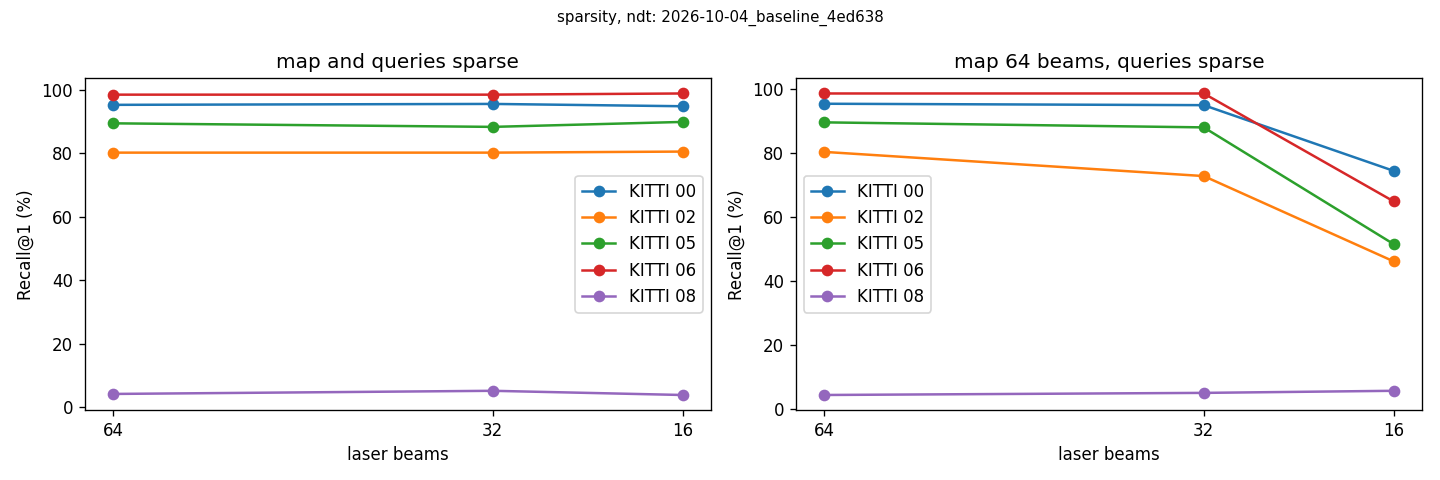

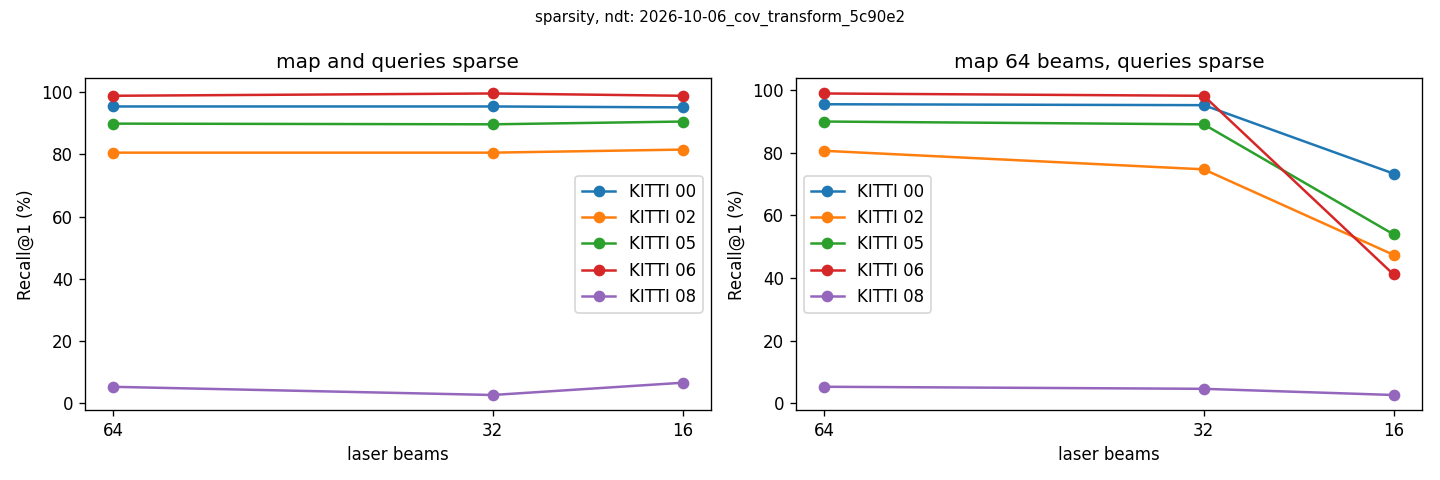

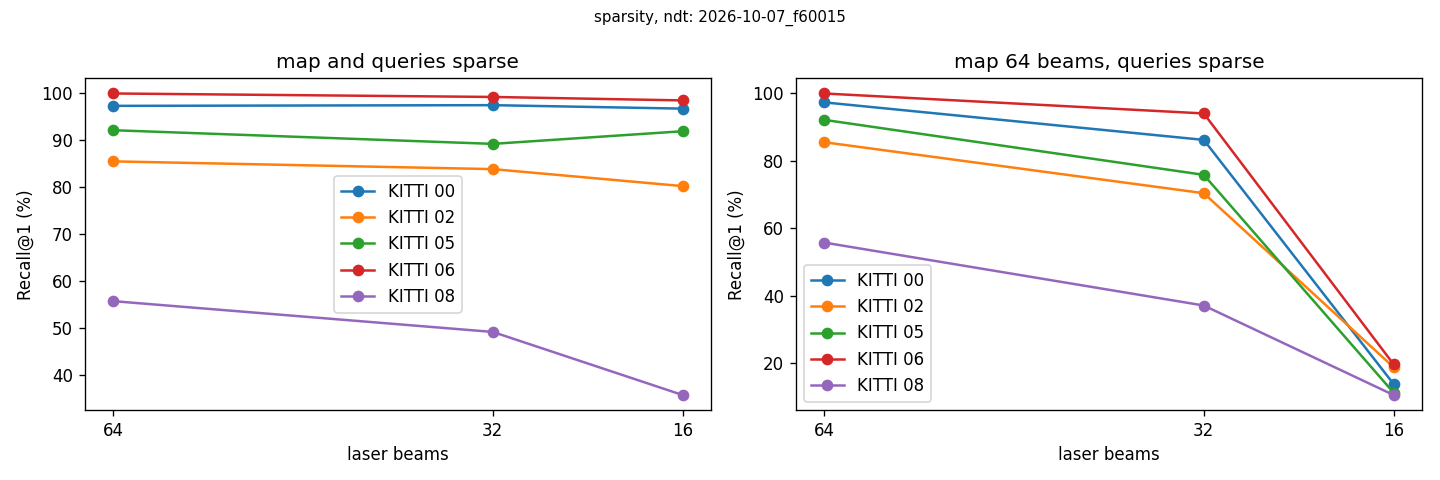

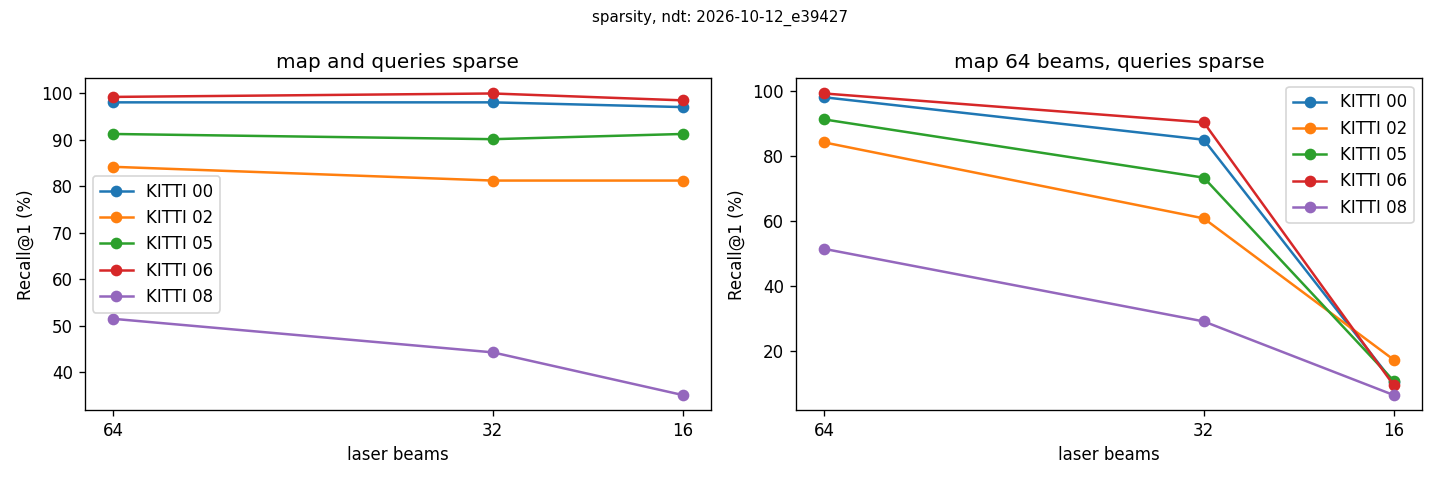

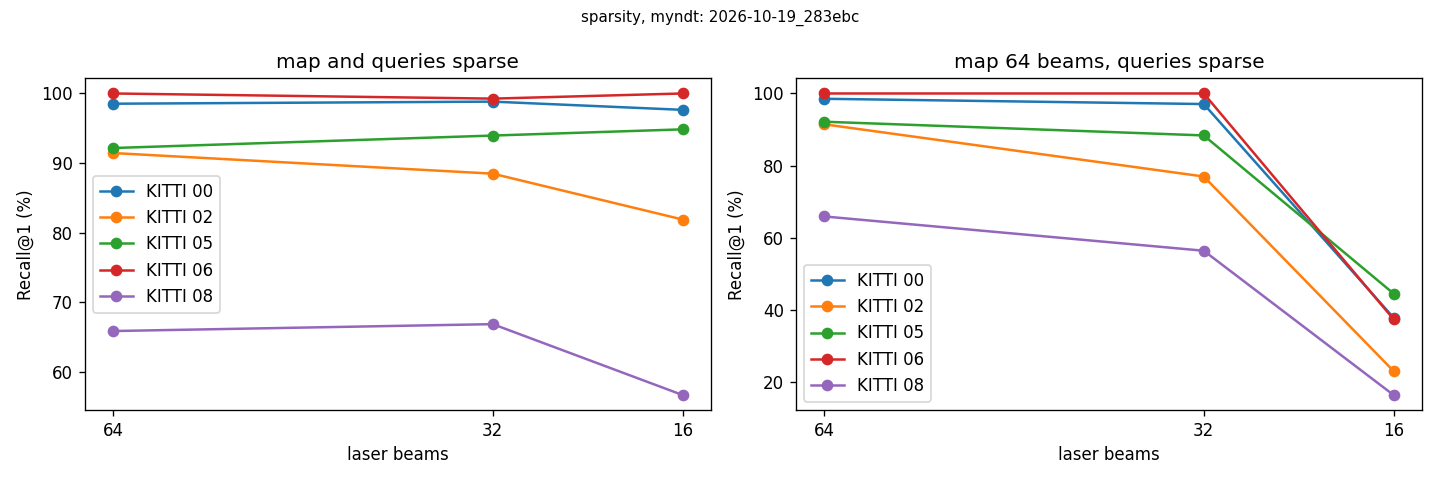

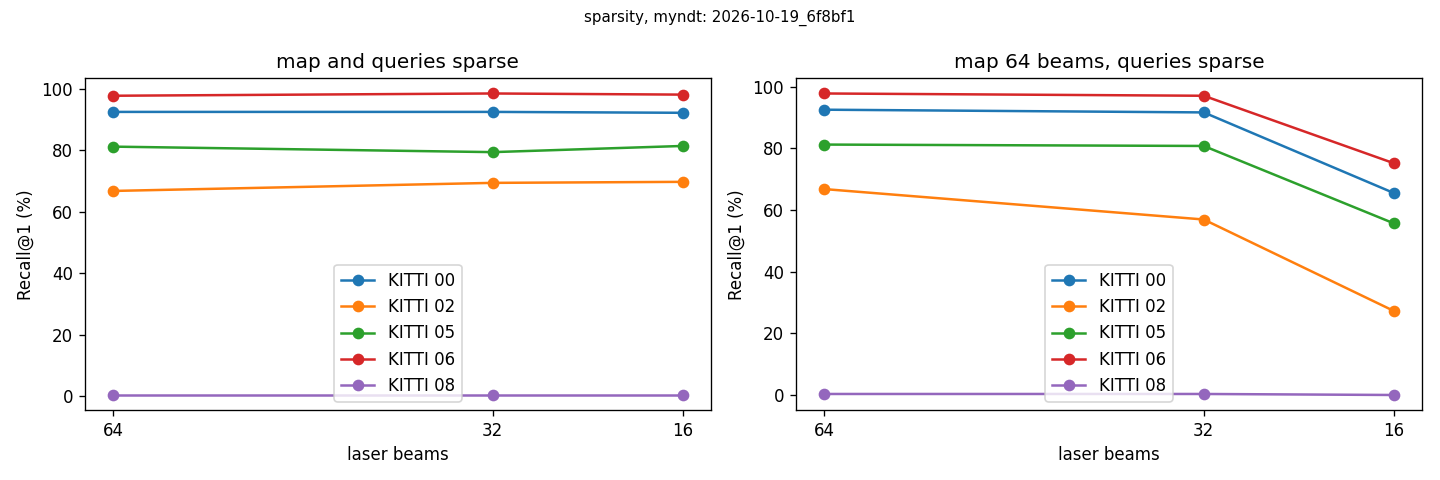

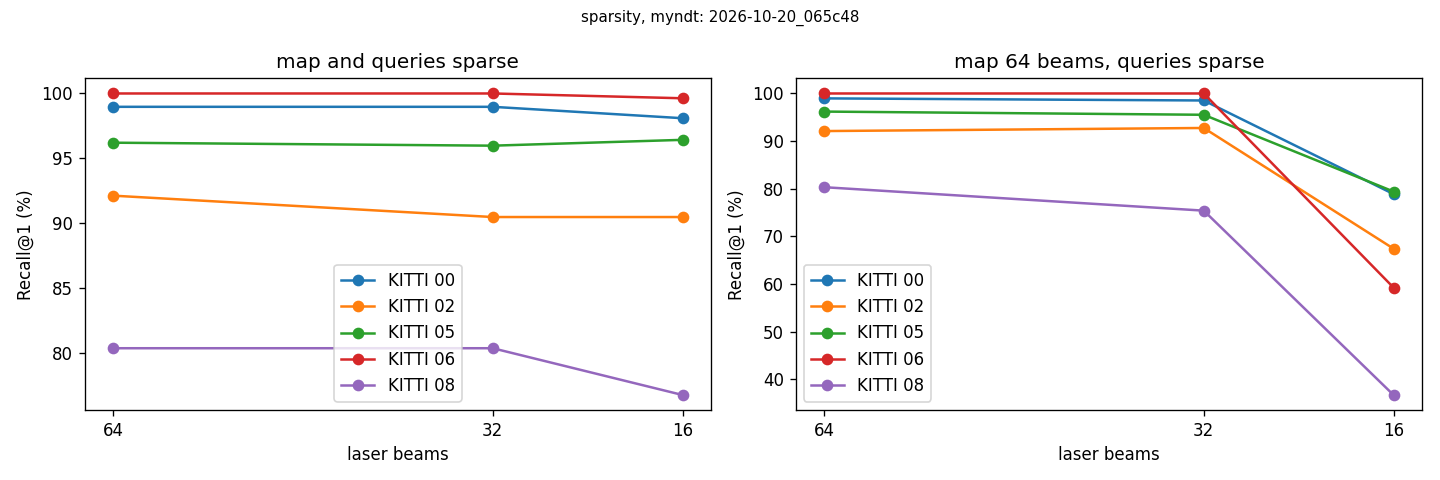

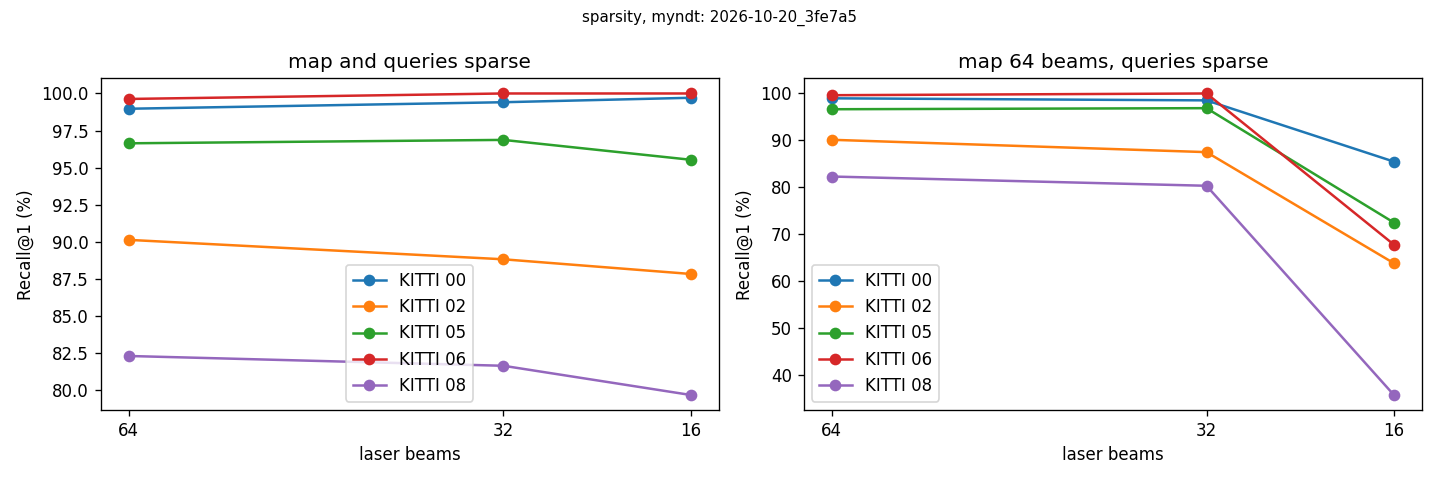

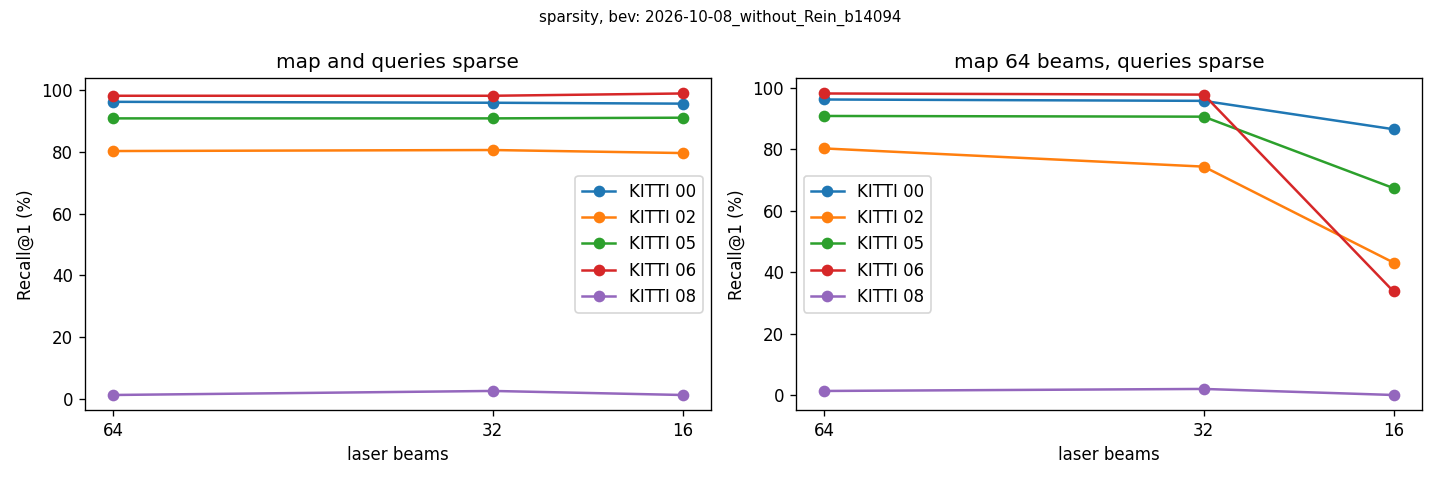

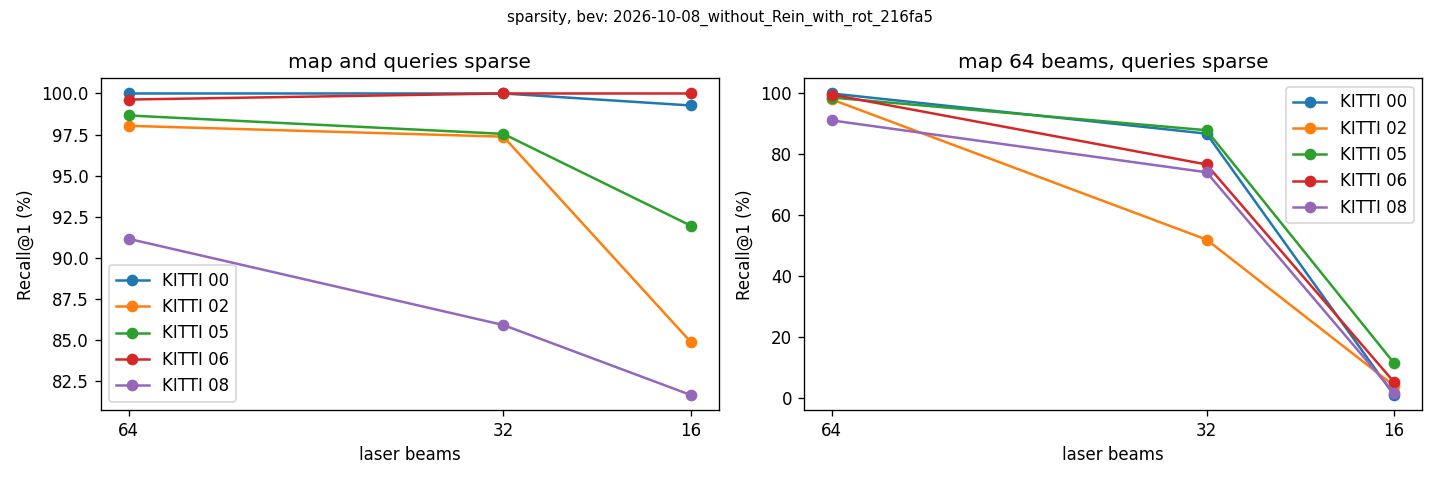

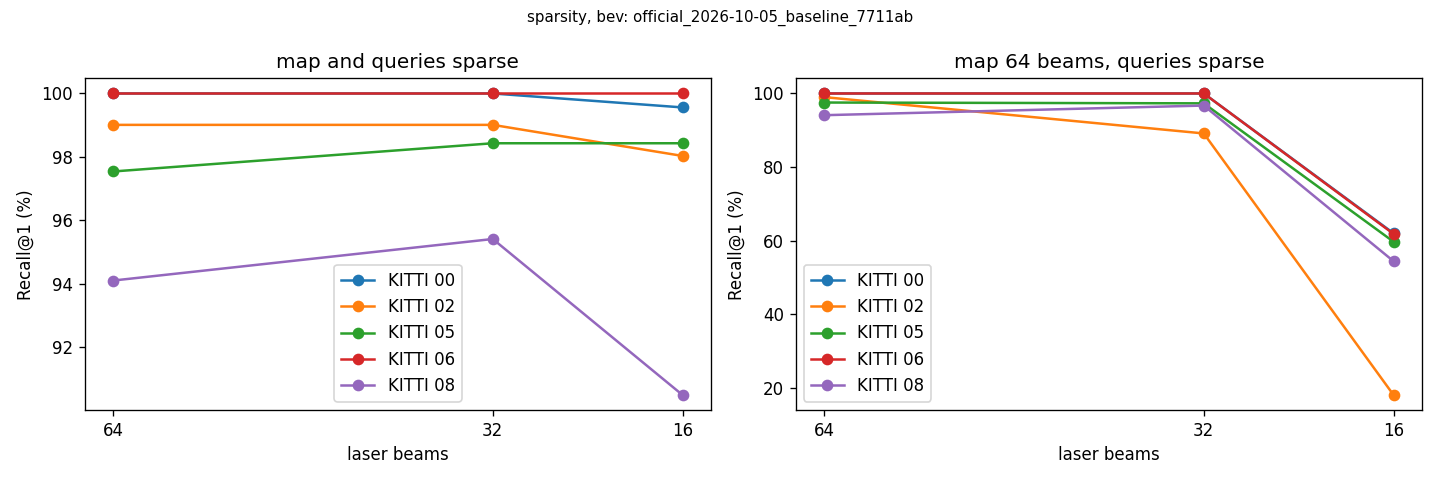

In [6]:
from IPython.display import Image, display
!python scripts/summarize_runs.py --drive {DRIVE} > /dev/null
e = pd.read_csv(f"{DRIVE}/evals_summary.csv", dtype={"seq": str, "run": str, "checkpoint": str})
sp = e[(e.eval_type == "sparsity") & e.run.isin(RUNS.run)].copy()
sp["beams"] = sp["beams"].astype(int)
sp.to_csv(f"{DRIVE}/sparsity_all_runs.csv", index=False)
print("->", f"{DRIVE}/sparsity_all_runs.csv")
for mode in SP["modes"]:
    t = sp[sp["mode"] == mode].pivot_table(index=["method", "run", "checkpoint"], columns=["beams", "seq"],
                                           values="R@1").sort_index(axis=1, level=0, ascending=False)
    print({"both": "MODE both: map and queries sparse", "query": "MODE query: map 64 beams, queries sparse"}[mode])
    display(t.round(2))
print("Mean Recall@1 over the sequences")
display(sp.pivot_table(index=["method", "run"], columns=["mode", "beams"], values="R@1", aggfunc="mean")
          .sort_index(axis=1, level=[0, 1], ascending=[True, False]).round(2))
for r in RUNS.itertuples():
    png = glob.glob(f"{r.run_dir}/eval/sparsity/*/sparsity.png")
    if png:
        display(Image(sorted(png)[-1]))

## 7. Density check: why some runs fail with a 64-beam map and 16-beam queries
`scripts/density_check.py`: descriptors of the same 400 scans (about 10 m apart) with 64 beams and with 32 / 16 beams.
- `self_top1`: % of sparse scans whose nearest 64-beam descriptor is the same scan (100 = density does not matter);
- `ratio`: distance scan(64) - same scan(sparse), divided by the typical distance between different scans (< 1 is good);
- `spread`: spread of the sparse descriptors relative to the 64-beam ones (well below 1 = they collapse together);
- `shift`: how far the mean sparse descriptor moved, in the same unit; `hub_share`: % of queries that all pick the same scan;
- `norm_64` / `norm_sparse`: descriptor norms (1 for L2-normalised heads).
Saved per run in `<run>/eval/density_check_<seq>.json`; not recomputed once there.

In [ ]:
CHECK_RUNS = ["2026-10-08_without_Rein_with_rot_216fa5", "2026-10-08_without_Rein_b14094",
              "official_2026-10-05_baseline_7711ab", "2026-10-07_f60015", "2026-10-04_baseline_4ed638",
              "2026-10-20_065c48", "2026-10-20_3fe7a5"]
CHECK_SEQS = ["08", "00"]
rows = []
for r in RUNS[RUNS.run.isin(CHECK_RUNS)].itertuples():
    for s in CHECK_SEQS:
        out = f"{r.run_dir}/eval/density_check_{s}.json"
        if not os.path.exists(out):
            os.makedirs(os.path.dirname(out), exist_ok=True)
            res = subprocess.run(["python", "scripts/density_check.py", "--method", r.method, "--run_dir", r.run_dir,
                                  "--ckpt", r.ckpt, "--data_dir", r.data_dir, "--kitti_root", KITTI, "--seq", s,
                                  "--out", out], capture_output=True, text=True, cwd="/content/lpr")
            if res.returncode:
                print(r.run, s, res.stdout[-500:], res.stderr[-1500:])
                continue
        rows += json.load(open(out))
DC = pd.DataFrame(rows)
if len(DC):
    DC.to_csv(f"{DRIVE}/density_check.csv", index=False)
    display(DC.drop(columns=["checkpoint", "n"]).set_index(["seq", "beams", "method", "run"]).sort_index())